# Relevance: do the adapter's replies fit the conversation?
StyleClassifier.ipynb (decision 19) says the adapter sounds like me, but it only looks at the reply. A reply can sound like me and have nothing to do with the conversation. The blind self-test was discarded because my memory contaminates it (decision 19), so fit is measured with a classifier of (context, reply) pairs.

_My prediction:_ I don't know. Ideally the replies should make sense: if it already learned my style, it should have picked up something of the context too. I'd say about 75% of the adapter's replies judged as fitting.


## Method
- **Pairs from real data only**, same session split as everything else (`data/style/`, `session/`):
  - fits (1): a context (last 6 turns, the training window) and my real reply to it;
  - doesn't fit (0): the same context and a real reply of mine from **another session** of the same split, drawn with seed 0 from the same length bin as the real one.

  Both replies are mine, so style can't separate them, and they have the same length distribution, so length can't either: the classifier has to look at the context.
- **Baselines:** length only (should be ~0.5 by construction, a check of the length matching) and TF-IDF word similarity between context and reply (lexical overlap).
- **Main model:** `mdeberta-v3-base` as a cross-encoder (context and reply in one input), fine-tuned on MPS, best epoch by valid AUC, saved under `models/`.
- **Scoring on the 1,133 test contexts**, frozen classifier: my real replies (ceiling), my replies from other conversations (floor), the adapter's and the base model's replies at temperature 1.0 (decision 19). Share judged as fitting (P ≥ 0.5) and mean P, 95% CI by session, position of the adapter = (adapter − floor) / (real − floor).
- **Known limit:** short generic replies ("vale", a laugh) fit almost anywhere, so some "doesn't fit" pairs actually fit. That lowers the ceiling for every set equally; it doesn't favour any of them.
- Only counts and metrics are printed, never text.

In [1]:
import json, math, os, random, time
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, accuracy_score

SEED = 0
TURNOS = 6          # context turns given to the classifier: the adapter's training window
MAX_LEN = 192       # tokens per (context, reply) pair; the context is cut from the left
MAX_CHARS_RESPUESTA = 300
MODELOS = "../models"
TRANSFORMER = "microsoft/mdeberta-v3-base"
BINS = [0, 10, 20, 40, 80, 160, 10**9]

def leer(ruta):
    with open(ruta) as f:
        return [json.loads(l) for l in f if l.strip()]

def texto_contexto(messages):
    # Last TURNOS turns before the reply, as plain text with who said it.
    turnos = [m for m in messages[:-1] if m["role"] != "system"][-TURNOS:]
    return "\n".join(("Me: " if m["role"] == "assistant" else "Friend: ") + m["content"] for m in turnos)

def bin_de(t):
    return next(i for i in range(len(BINS) - 1) if BINS[i] <= len(t) < BINS[i + 1])

## Data
Contexts from `session/{train,valid}.jsonl` and, for test, `session_ctx20/test.jsonl` cut to the same 6 turns. Replies and sessions from `data/style/` (my replies without the canary).

In [2]:
fuentes = {"train": "../data/dataset/session/train.jsonl", "valid": "../data/dataset/session/valid.jsonl",
           "test": "../data/dataset/session_ctx20/test.jsonl"}
base = {}
for split, ruta in fuentes.items():
    ejemplos = leer(ruta)
    mios = [r for r in leer(f"../data/style/{split}.jsonl") if r["label"] == 1]
    assert len(ejemplos) == len(mios)
    # session/train has the canary appended to 5 replies; the style rows don't
    assert all(e["messages"][-1]["content"].startswith(m["text"]) for e, m in zip(ejemplos, mios))
    base[split] = {"contexto": [texto_contexto(e["messages"]) for e in ejemplos],
                   "respuesta": [m["text"] for m in mios], "sesion": [m["session"] for m in mios]}

def emparejar_mal(split, semilla):
    # For each context, a reply of mine from another session, same length bin, drawn with a fixed seed.
    rng = random.Random(semilla)
    d = base[split]
    por_bin = defaultdict(list)
    for j, r in enumerate(d["respuesta"]):
        por_bin[bin_de(r)].append(j)
    elegidas = []
    for i, r in enumerate(d["respuesta"]):
        candidatas = por_bin[bin_de(r)]
        while True:
            j = rng.choice(candidatas)
            if d["sesion"][j] != d["sesion"][i]:
                break
        elegidas.append(d["respuesta"][j])
    return elegidas

pares = {}
for split in ["train", "valid", "test"]:
    d = base[split]
    malas = emparejar_mal(split, SEED)
    pares[split] = {"contexto": d["contexto"] * 2, "respuesta": d["respuesta"] + malas,
                    "etiqueta": np.array([1] * len(malas) + [0] * len(malas)), "sesion": d["sesion"] * 2}
    print(f"{split:>5}: {len(d['respuesta'])} contexts -> {len(pares[split]['etiqueta'])} pairs (half fit) | sessions {len(set(d['sesion']))}")

train: 5404 contexts -> 10808 pairs (half fit) | sessions 463
valid: 1012 contexts -> 2024 pairs (half fit) | sessions 60
 test: 1133 contexts -> 2266 pairs (half fit) | sessions 63


## Baselines

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer

def imprimir(nombre, puntuar):
    v = roc_auc_score(pares["valid"]["etiqueta"], puntuar("valid"))
    t = roc_auc_score(pares["test"]["etiqueta"], puntuar("test"))
    print(f"{nombre:<16} valid auc {v:.3f} | test auc {t:.3f}")

# A: length of the reply only. Length-matched negatives, so this should sit near 0.5.
longitud = LogisticRegression().fit(np.log1p([[len(r)] for r in pares["train"]["respuesta"]]), pares["train"]["etiqueta"])
imprimir("length", lambda s: longitud.predict_proba(np.log1p([[len(r)] for r in pares[s]["respuesta"]]))[:, 1])

# B: TF-IDF word similarity between context and reply (no training on labels, only the vocabulary).
tfidf = TfidfVectorizer(min_df=2, sublinear_tf=True).fit(base["train"]["contexto"] + base["train"]["respuesta"])
def similitud(contextos, respuestas):
    a, b = tfidf.transform(contextos), tfidf.transform(respuestas)
    return np.asarray(a.multiply(b).sum(axis=1)).ravel()  # rows are L2-normalised: this is the cosine
imprimir("tfidf similarity", lambda s: similitud(pares[s]["contexto"], pares[s]["respuesta"]))

length           valid auc 0.500 | test auc 0.500
tfidf similarity valid auc 0.592 | test auc 0.602


## Cross-encoder
Same MPS setup as StyleClassifier.ipynb: fp32, fixed padding, memory capped at half of what macOS recommends. Batch 16, lr 2e-5 with 10% warmup, up to 3 epochs, best by valid AUC (patience 1), saved under `models/` so running it again just loads it. If MPS runs out of memory, lower `lote` to 8.

In [4]:
import torch
torch.mps.set_per_process_memory_fraction(0.5)
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

DISPOSITIVO = "mps" if torch.backends.mps.is_available() else "cpu"
RUTA_MODELO = f"{MODELOS}/fit_{TRANSFORMER.split('/')[-1]}"

MAX_TOKENS_RESPUESTA = 128  # my real replies are at most ~100 tokens; only some base-model rambles are longer

def recortar(tok, r):
    # Cap the reply in characters and in tokens, so the context always has room
    # (truncation="only_first" fails if the reply alone doesn't fit).
    r = r[:MAX_CHARS_RESPUESTA]
    piezas = tok.tokenize(r)
    return r if len(piezas) <= MAX_TOKENS_RESPUESTA else tok.convert_tokens_to_string(piezas[:MAX_TOKENS_RESPUESTA])

def codificar(tok, contextos, respuestas):
    # Context first, cut from the left (the end of the conversation matters most); reply capped as above.
    return tok(list(contextos), [recortar(tok, r) for r in respuestas], truncation="only_first",
               max_length=MAX_LEN, padding="max_length", return_tensors="pt").to(DISPOSITIVO)

def probabilidades(modelo, tok, contextos, respuestas, lote=64):
    modelo.eval()
    salida = []
    with torch.no_grad():
        for i in range(0, len(contextos), lote):
            x = codificar(tok, contextos[i:i + lote], respuestas[i:i + lote])
            salida.append(torch.softmax(modelo(**x).logits.float(), dim=-1)[:, 1].cpu().numpy())
    torch.mps.empty_cache()
    return np.concatenate(salida)

def entrenar(epocas=3, lote=16, lr=2e-5, paciencia=1):
    tok = AutoTokenizer.from_pretrained(TRANSFORMER, truncation_side="left")
    modelo = AutoModelForSequenceClassification.from_pretrained(TRANSFORMER, num_labels=2, dtype=torch.float32).to(DISPOSITIVO)
    torch.manual_seed(SEED)
    optim = torch.optim.AdamW(modelo.parameters(), lr=lr, weight_decay=0.01)
    tr = pares["train"]
    pasos = epocas * math.ceil(len(tr["etiqueta"]) / lote)
    plan = get_linear_schedule_with_warmup(optim, int(0.1 * pasos), pasos)
    orden = np.random.default_rng(SEED)
    mejor, sin_mejora = -1, 0
    for epoca in range(epocas):
        modelo.train()
        indices = orden.permutation(len(tr["etiqueta"]))
        inicio = time.time()
        for k in range(0, len(indices), lote):
            idx = indices[k:k + lote]
            x = codificar(tok, [tr["contexto"][i] for i in idx], [tr["respuesta"][i] for i in idx])
            y = torch.tensor(tr["etiqueta"][idx], device=DISPOSITIVO)
            modelo(**x, labels=y).loss.backward()
            optim.step(); plan.step(); optim.zero_grad()
            if (k // lote) % 50 == 0:
                torch.mps.empty_cache()
            if (k // lote) % 200 == 0:
                print(f"  epoch {epoca + 1}: {k}/{len(indices)} pairs ({(time.time() - inicio) / 60:.1f} min)")
        auc = roc_auc_score(pares["valid"]["etiqueta"], probabilidades(modelo, tok, pares["valid"]["contexto"], pares["valid"]["respuesta"]))
        print(f"epoch {epoca + 1}: valid auc {auc:.3f} ({(time.time() - inicio) / 60:.1f} min)")
        if auc > mejor:
            mejor, sin_mejora = auc, 0
            modelo.save_pretrained(RUTA_MODELO); tok.save_pretrained(RUTA_MODELO)
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:
                break

if not os.path.exists(RUTA_MODELO):
    entrenar()
    torch.mps.empty_cache()
tok_f = AutoTokenizer.from_pretrained(RUTA_MODELO, truncation_side="left")
modelo_f = AutoModelForSequenceClassification.from_pretrained(RUTA_MODELO, dtype=torch.float32).to(DISPOSITIVO)
encaja = lambda contextos, respuestas: probabilidades(modelo_f, tok_f, contextos, respuestas)

for s in ["valid", "test"]:
    p = encaja(pares[s]["contexto"], pares[s]["respuesta"])
    print(f"cross-encoder {s}: auc {roc_auc_score(pares[s]['etiqueta'], p):.3f} | acc {accuracy_score(pares[s]['etiqueta'], p >= 0.5):.3f}")

.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

cross-encoder valid: auc 0.563 | acc 0.500


KeyboardInterrupt: 

> **Not run.** The cross-encoder didn't learn: valid AUC 0.563, test 0.567, accuracy 0.500 (it gives every pair the same class), below plain TF-IDF similarity (0.60). A threshold on it says nothing, so the two scoring cells below are left as they were, unrun. Fit is measured in the next section instead. They are kept as raw cells, so they can't be run by accident.


## Scoring
The same 1,133 test contexts with four replies each: mine (ceiling), mine from another conversation (floor, the same draw as the test pairs above), the adapter's and the base model's at temperature 1.0. Bootstrap over test sessions (1000, seed 0), jointly for all sets.

## Context dependence (NLL with vs without context)
A different way to ask "does it fit": how much does the conversation help to predict the reply? For each test context and each reply, the NLL per token of the reply **with** the context (system prompt + last 6 turns) and **without** it (system prompt only). Gain = NLL without context − NLL with context. A reply that fits this conversation becomes much more predictable when the model sees it; a reply from another conversation, much less.

- **Scorer:** `Qwen2.5-1.5B-Instruct-4bit`, no adapter. It generated none of the four sets, so it doesn't favour its own text.
- **Same metric as always:** `nll_ejemplo`, only the reply tokens, token-weighted means (same tokens in both conditions).
- **Sets:** my real reply (ceiling), a real reply of mine from another session of the same length bin (floor, the same draw as above), the adapter's and the base model's at temperature 1.0. Replies capped at 300 characters, as above.
- 95% CI resampling test sessions (1000, seed 0), position of the adapter = (adapter − floor) / (real − floor). Per-example results cached in `results/relevance_nll.json` (resumable). ~9,000 forward passes, about 15-20 min.

In [5]:
import mlx.core as mx
from mlx_lm import load

JUEZ = "mlx-community/Qwen2.5-1.5B-Instruct-4bit"
CACHE_NLL = "results/relevance_nll.json"

# Copied as is from Perplexity.ipynb
def nll_ejemplo(model, tokenizer, messages):
    full = tokenizer.apply_chat_template(messages)
    base_prompt = tokenizer.apply_chat_template(
        messages[:-1], add_generation_prompt=True)
    n_tokens = len(full) - len(base_prompt)
    logits = model(mx.array(full)[None])
    logits = logits[0, len(base_prompt)-1:len(full)-1]
    logits = logits.astype(mx.float32)
    logprobs = logits - mx.logsumexp(logits, axis=-1, keepdims=True)
    nll = 0
    for i in range(n_tokens):
        nll -= logprobs[i, full[len(base_prompt) + i]].item()
    mx.clear_cache()
    return (nll, n_tokens)

ejemplos_test = leer(fuentes["test"])
def mensajes(k, respuesta, con_contexto):
    # System prompt (+ the last TURNOS turns) + the reply as the assistant's turn.
    msgs = ejemplos_test[k]["messages"]
    turnos = [m for m in msgs[:-1] if m["role"] != "system"][-TURNOS:] if con_contexto else []
    return [msgs[0]] + turnos + [{"role": "assistant", "content": respuesta[:MAX_CHARS_RESPUESTA]}]

conjuntos_nll = {
    "floor (other conv.)": pares["test"]["respuesta"][len(base["test"]["respuesta"]):],
    "base t1.0": [g["text"] for g in leer("../data/style/generations_base_t1.jsonl")],
    "adapter t1.0": [g["text"] for g in leer("../data/style/generations_adapter_t1.jsonl")],
    "real (me)": base["test"]["respuesta"],
}
assert all(len(v) == len(ejemplos_test) for v in conjuntos_nll.values())
assert ejemplos_test[0]["messages"][0]["role"] == "system"

In [6]:
nll = json.load(open(CACHE_NLL)) if os.path.exists(CACHE_NLL) else {}
juez, tok_juez = load(JUEZ)
inicio = time.time()
for nombre, respuestas in conjuntos_nll.items():
    filas = nll.setdefault(nombre, [])  # per example: [nll_ctx, n_ctx, nll_noctx, n_noctx]
    for k in range(len(filas), len(respuestas)):
        a = nll_ejemplo(juez, tok_juez, mensajes(k, respuestas[k], True))
        b = nll_ejemplo(juez, tok_juez, mensajes(k, respuestas[k], False))
        filas.append([a[0], a[1], b[0], b[1]])
        if (k + 1) % 100 == 0 or k + 1 == len(respuestas):
            with open(CACHE_NLL, "w") as f:
                json.dump(nll, f)
            print(f"{nombre}: {k + 1}/{len(respuestas)} ({(time.time() - inicio) / 60:.1f} min)")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

floor (other conv.): 100/1133 (0.4 min)
floor (other conv.): 200/1133 (0.8 min)
floor (other conv.): 300/1133 (1.1 min)
floor (other conv.): 400/1133 (1.5 min)
floor (other conv.): 500/1133 (1.8 min)
floor (other conv.): 600/1133 (2.2 min)
floor (other conv.): 700/1133 (2.6 min)
floor (other conv.): 800/1133 (2.9 min)
floor (other conv.): 900/1133 (3.3 min)
floor (other conv.): 1000/1133 (3.7 min)
floor (other conv.): 1100/1133 (4.1 min)
floor (other conv.): 1133/1133 (4.2 min)
base t1.0: 100/1133 (4.7 min)
base t1.0: 200/1133 (5.2 min)
base t1.0: 300/1133 (5.7 min)
base t1.0: 400/1133 (6.2 min)
base t1.0: 500/1133 (6.7 min)
base t1.0: 600/1133 (7.2 min)
base t1.0: 700/1133 (7.7 min)
base t1.0: 800/1133 (8.1 min)
base t1.0: 900/1133 (8.7 min)
base t1.0: 1000/1133 (9.2 min)
base t1.0: 1100/1133 (9.7 min)
base t1.0: 1133/1133 (9.8 min)
adapter t1.0: 100/1133 (10.2 min)
adapter t1.0: 200/1133 (10.6 min)
adapter t1.0: 300/1133 (11.0 min)
adapter t1.0: 400/1133 (11.3 min)
adapter t1.0: 500/

floor (other conv.)  NLL with context 4.384 | without 5.183 | gain +0.798 [+0.682, +0.872]
base t1.0            NLL with context 5.088 | without 5.354 | gain +0.267 [+0.247, +0.279]
adapter t1.0         NLL with context 5.103 | without 5.952 | gain +0.849 [+0.742, +0.916]
real (me)            NLL with context 4.127 | without 5.171 | gain +1.044 [+0.930, +1.118]
position of the adapter: 0.20 [-0.11, 0.45]  (0 = a reply from another conversation, 1 = my real reply)


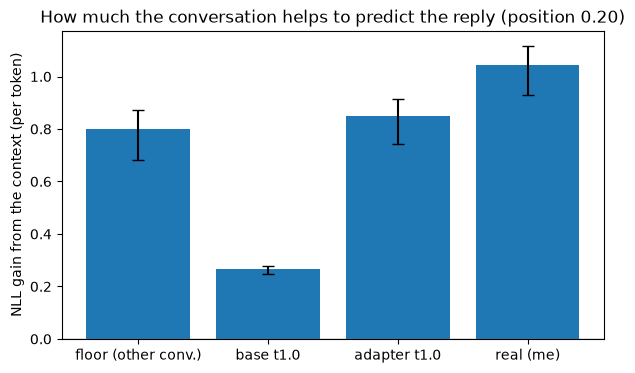

In [7]:
sesion_test = base["test"]["sesion"]
sumas_nll = {}
for nombre, filas in nll.items():
    s_ = defaultdict(lambda: np.zeros(3))  # nll with context, nll without, tokens
    for (a, n, b, n2), ses in zip(filas, sesion_test):
        assert n == n2  # same reply tokens in both conditions
        s_[ses] += (a, b, n)
    sumas_nll[nombre] = dict(s_)

def ganancia(sum_, elegidas):
    tot = sum(sum_[s] for s in elegidas)
    return (tot[1] - tot[0]) / tot[2]  # NLL per token without context - with context

sesiones = sorted(set(sesion_test))
random.seed(SEED)
rem = {k: [] for k in nll} | {"position": []}
for _ in range(1000):
    elegidas = random.choices(sesiones, k=len(sesiones))
    g = {k: ganancia(sumas_nll[k], elegidas) for k in nll}
    for k in nll:
        rem[k].append(g[k])
    rem["position"].append((g["adapter t1.0"] - g["floor (other conv.)"]) / (g["real (me)"] - g["floor (other conv.)"]))

res_nll = {}
for k in nll:
    tot = sum(sumas_nll[k].values())
    lo, hi = np.percentile(rem[k], [2.5, 97.5])
    res_nll[k] = {"nll_ctx": tot[0] / tot[2], "nll_noctx": tot[1] / tot[2], "gain": (tot[1] - tot[0]) / tot[2], "ci": [float(lo), float(hi)]}
    print(f"{k:<20} NLL with context {tot[0] / tot[2]:.3f} | without {tot[1] / tot[2]:.3f} | gain {res_nll[k]['gain']:+.3f} [{lo:+.3f}, {hi:+.3f}]")
posicion_nll = (res_nll["adapter t1.0"]["gain"] - res_nll["floor (other conv.)"]["gain"]) / \
               (res_nll["real (me)"]["gain"] - res_nll["floor (other conv.)"]["gain"])
lo, hi = np.percentile(rem["position"], [2.5, 97.5])
print(f"position of the adapter: {posicion_nll:.2f} [{lo:.2f}, {hi:.2f}]  (0 = a reply from another conversation, 1 = my real reply)")

with open("results/relevance.json", "w") as f:
    json.dump({"source": "experiments/Relevance.ipynb", "scorer": JUEZ, "context_turns": TURNOS,
               "context_gain": res_nll, "position": {"value": posicion_nll, "ci": [float(lo), float(hi)]},
               "cross_encoder": {"valid_auc": 0.563, "test_auc": 0.567, "note": "did not learn, not used"}}, f, indent=2)

orden_ = list(res_nll)
ys = [res_nll[k]["gain"] for k in orden_]
err = [[y - res_nll[k]["ci"][0] for y, k in zip(ys, orden_)], [res_nll[k]["ci"][1] - y for y, k in zip(ys, orden_)]]
fig, eje = plt.subplots(figsize=(7, 4))
eje.bar(orden_, ys, yerr=err, capsize=4)
eje.axhline(0, color="gray", linewidth=1)
eje.set_ylabel("NLL gain from the context (per token)")
eje.set_title(f"How much the conversation helps to predict the reply (position {posicion_nll:.2f})")
plt.show()

### Conclusion

NLL gain per token from the context (without − with), scorer Qwen2.5-1.5B, 1,133 test contexts, 95% CI by session:

| reply | gain | NLL with context | NLL without |
|---|---|---|---|
| my real reply | 1.04 [0.93, 1.12] | 4.13 | 5.17 |
| adapter, temp 1.0 | 0.85 [0.74, 0.92] | 5.10 | 5.95 |
| mine, from another conversation (floor) | 0.80 [0.68, 0.87] | 4.38 | 5.18 |
| base, temp 1.0 | 0.27 [0.25, 0.28] | 5.09 | 5.35 |

Position of the adapter between floor and my real reply: 0.20 [−0.11, 0.45].

The adapter sounds like me (StyleClassifier.ipynb), but it barely answers what it's told. Against the base model it improves a lot (0.27 to 0.85), but a reply of mine taken from another conversation, which by definition doesn't answer anything in this one, already gets 0.80. Most of what the context gives is the register (a short, informal WhatsApp chat in Spanish), not the content. The part that really means "this answers that" is the band from 0.80 to 1.04, and the adapter covers only 20% of it, with a CI that includes 0. Its replies would be worth almost the same in another chat. Even with the context, the scorer finds them much less expected than mine (5.10 vs 4.13).

My prediction (about 75% of its replies fitting) was for the cross-encoder, which didn't learn (valid AUC 0.56, accuracy 0.50: same class for everything, below plain TF-IDF similarity at 0.60). With so many short generic replies of mine that fit anywhere, (context, random reply of mine) is a hard task with noisy labels. But the spirit of the prediction was that it would fit more than it does.

Caveats: the scorer is a 1.5B model that sees 6 turns; the gain mixes register and content, which is why the floor is essential. The base model's replies are 3.5x longer and assistant-like, so its comparison is confounded by length and register; adapter, floor and real have the same length (17-18 tokens). This doesn't tell whether the limit is capacity, data, or both.